# EDA — panel AMG 2020-2025
Jorge Flores Uribe

In [19]:
import sqlite3, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd()
DB = BASE.parent / "mcdi tesis" / "db" / "tesis_panel.db"
FIG = BASE / "figuras"; FIG.mkdir(exist_ok=True)
TAB = BASE / "tablas"; TAB.mkdir(exist_ok=True)
assert DB.exists(), DB

plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "figure.dpi": 120,
                     "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
con = sqlite3.connect(DB)

## 1. Base depurada

In [20]:
tablas = pd.read_sql("select name from sqlite_master where type='table'", con)["name"].tolist()
desc = {
    "repd_amg_casos": "Casos del REPD en el AMG, 2020--2025",
    "panel_municipio_trimestre": "Panel balanceado municipio $\\times$ trimestre",
    "cedulas_amg": "Cédulas pseudonimizadas",
    "ensu_cb_amg": "Respuestas individuales de la ENSU",
    "ensu_indice_municipio": "Índice ENSU ponderado por municipio y año",
    "cnb_colonias_amg": "Conteos de la CNB por colonia",
    "cnb_colonia_mes_amg": "Conteos de la CNB por colonia y mes",
}
rows = []
for t in tablas:
    n = pd.read_sql(f'select count(*) n from "{t}"', con)["n"][0]
    k = len(pd.read_sql(f'pragma table_info("{t}")', con))
    rows.append({"tabla": t, "contenido": desc.get(t, ""), "registros": n, "variables": k})
base = pd.DataFrame(rows)
base

,tabla,contenido,registros,variables
0,repd_amg_casos,"Casos del REPD en el AMG, 2020--2025",18142,26
1,panel_municipio_trimestre,Panel balanceado municipio $\times$ trimestre,216,16
2,cedulas_amg,Cédulas pseudonimizadas,6626,14
3,ensu_cb_amg,Respuestas individuales de la ENSU,5715,18
4,ensu_indice_municipio,Índice ENSU ponderado por municipio y año,20,8
5,cnb_colonias_amg,Conteos de la CNB por colonia,1411,11
6,cnb_colonia_mes_amg,Conteos de la CNB por colonia y mes,623,16


In [21]:
panel = pd.read_sql("select * from panel_municipio_trimestre", con)
casos = pd.read_sql("select * from repd_amg_casos", con)
ensu_idx = pd.read_sql("select * from ensu_indice_municipio", con)
print(panel.shape, casos.shape, ensu_idx.shape)
print("Nulos por columna del panel:")
print(panel.isna().sum()[panel.isna().sum() > 0])

(216, 16) (18142, 26) (20, 8)
Nulos por columna del panel:
pct_mujeres             4
pct_sin_vida            4
pct_sigue_desap         4
pct_victima_delito      4
poblacion             216
tasa_trim             216
pct_inseg_ciudad      136
pct_espera_mal        136
pct_victima           136
pct_desempeno_malo    136
dtype: int64


## 2. Población y tasa
Población del Censo 2020. Tasa = casos / población × 100,000.

In [22]:
POB_2020 = {  # Censo de Población y Vivienda 2020, INEGI
    "039": 1_385_629,  # Guadalajara
    "120": 1_476_491,  # Zapopan
    "098":   687_127,  # San Pedro Tlaquepaque
    "101":   569_913,  # Tonalá
    "097":   727_750,  # Tlajomulco de Zúñiga
    "070":   232_852,  # El Salto
    "044":    67_969,  # Ixtlahuacán de los Membrillos
    "051":    30_855,  # Juanacatlán
    "124":    64_806,  # Zapotlanejo
}
CENTRALES = {"039", "120", "098", "101"}
CORTO = {"GUADALAJARA": "Guadalajara", "ZAPOPAN": "Zapopan", "SAN PEDRO TLAQUEPAQUE": "Tlaquepaque",
         "TONALA": "Tonalá", "TLAJOMULCO DE ZUNIGA": "Tlajomulco", "EL SALTO": "El Salto",
         "IXTLAHUACAN DE LOS MEMBRILLOS": "Ixtlahuacán", "JUANACATLAN": "Juanacatlán",
         "ZAPOTLANEJO": "Zapotlanejo"}

panel["poblacion"] = panel["cve_mun"].map(POB_2020).astype(float)
panel["tasa_trim"] = panel["casos"] / panel["poblacion"] * 1e5
panel["tipo"] = np.where(panel["cve_mun"].isin(CENTRALES), "Central", "Periférico")
panel["mun"] = panel["nom_mun"].map(CORTO)
panel["periodo"] = panel["anio"].astype(str) + "T" + panel["trimestre"].astype(str)
assert panel["tasa_trim"].notna().all() and len(panel) == 216
print("Población AMG (9 municipios):", f"{sum(POB_2020.values()):,}")
panel.head()

Población AMG (9 municipios): 5,243,392


,cve_mun,anio,trimestre,casos,pct_mujeres,pct_sin_vida,pct_sigue_desap,pct_victima_delito,nom_mun,periodo,poblacion,tasa_trim,pct_inseg_ciudad,pct_espera_mal,pct_victima,pct_desempeno_malo,tipo,mun
0,039,2020,1,255,0.317647,0.121569,0.184314,0.196078,GUADALAJARA,2020T1,1385629.0,18.403195,NaN,NaN,NaN,NaN,Central,Guadalajara
1,039,2020,2,208,0.293269,0.091346,0.139423,0.173077,GUADALAJARA,2020T2,1385629.0,15.011233,NaN,NaN,NaN,NaN,Central,Guadalajara
2,039,2020,3,178,0.314607,0.073034,0.213483,0.162921,GUADALAJARA,2020T3,1385629.0,12.846151,NaN,NaN,NaN,NaN,Central,Guadalajara
3,039,2020,4,196,0.321429,0.102041,0.173469,0.183673,GUADALAJARA,2020T4,1385629.0,14.145200,NaN,NaN,NaN,NaN,Central,Guadalajara
4,039,2021,1,212,0.283019,0.094340,0.193396,0.113208,GUADALAJARA,2021T1,1385629.0,15.299911,NaN,NaN,NaN,NaN,Central,Guadalajara


## 3. Resúmenes estadísticos

In [23]:
VARS = {
    "casos": "Casos por trimestre",
    "tasa_trim": "Tasa trimestral (por 100 mil hab.)",
    "pct_mujeres": "Proporción de mujeres",
    "pct_sigue_desap": "Proporción aún desaparecida",
    "pct_sin_vida": "Proporción localizada sin vida",
    "pct_victima_delito": "Proporción víctima de delito",
    "pct_inseg_ciudad": "ENSU: percepción de inseguridad",
    "pct_espera_mal": "ENSU: expectativa desfavorable",
    "pct_victima": "ENSU: victimización en el hogar",
    "pct_desempeno_malo": "ENSU: desempeño percibido como malo",
}
d = panel[list(VARS)].agg(["count", "mean", "median", "std", "min", "max"]).T
d.columns = ["n", "media", "mediana", "de", "min", "max"]
d["cv"] = d["de"] / d["media"]
d.index = [VARS[v] for v in d.index]
descriptivos = d
descriptivos.round(3)

,n,media,mediana,de,min,max,cv
Casos por trimestre,216.0,83.991,63.500,80.966,0.000,284.000,0.964
Tasa trimestral (por 100 mil hab.),216.0,14.068,13.574,6.673,0.000,51.964,0.474
Proporción de mujeres,212.0,0.243,0.248,0.128,0.000,1.000,0.529
Proporción aún desaparecida,212.0,0.299,0.281,0.164,0.000,1.000,0.550
Proporción localizada sin vida,212.0,0.083,0.055,0.103,0.000,0.727,1.240
Proporción víctima de delito,212.0,0.173,0.148,0.137,0.000,1.000,0.791
ENSU: percepción de inseguridad,80.0,0.675,0.656,0.096,0.531,0.849,0.142
ENSU: expectativa desfavorable,80.0,0.620,0.621,0.094,0.418,0.765,0.152
ENSU: victimización en el hogar,80.0,0.517,0.521,0.100,0.361,0.718,0.193
ENSU: desempeño percibido como malo,80.0,0.751,0.733,0.060,0.637,0.841,0.081


In [24]:
# Por municipio
g = panel.groupby(["cve_mun", "mun", "tipo"])
por_mun = g.agg(casos=("casos", "sum"), pob=("poblacion", "first"),
                tasa_media=("tasa_trim", "mean"), tasa_mediana=("tasa_trim", "median"),
                tasa_de=("tasa_trim", "std"), tasa_min=("tasa_trim", "min"),
                tasa_max=("tasa_trim", "max")).reset_index()
por_mun["cv"] = por_mun["tasa_de"] / por_mun["tasa_media"]
por_mun["tasa_anual"] = por_mun["tasa_media"] * 4
por_mun["pct_casos"] = por_mun["casos"] / por_mun["casos"].sum()
por_mun = por_mun.sort_values("tasa_media", ascending=False)
por_mun.round(2)

,cve_mun,mun,tipo,casos,pob,tasa_media,tasa_mediana,tasa_de,tasa_min,tasa_max,cv,tasa_anual,pct_casos
3,070,El Salto,Periférico,1047,232852.0,18.74,15.89,12.07,5.58,51.96,0.64,74.94,0.06
1,044,Ixtlahuacán,Periférico,275,67969.0,16.86,16.18,6.21,7.36,27.95,0.37,67.43,0.02
0,039,Guadalajara,Central,5320,1385629.0,16.00,15.26,2.74,11.11,20.28,0.17,63.99,0.29
4,097,Tlajomulco,Periférico,2683,727750.0,15.36,15.39,3.74,7.69,22.67,0.24,61.45,0.15
7,120,Zapopan,Central,4801,1476491.0,13.55,13.92,3.38,7.79,19.23,0.25,54.19,0.26
5,098,Tlaquepaque,Central,2216,687127.0,13.44,13.68,2.13,9.17,17.46,0.16,53.75,0.12
2,051,Juanacatlán,Periférico,85,30855.0,11.48,9.72,9.75,0.00,35.65,0.85,45.91,0.00
6,101,Tonalá,Central,1563,569913.0,11.43,11.14,2.77,6.84,18.42,0.24,45.71,0.09
8,124,Zapotlanejo,Periférico,152,64806.0,9.77,9.26,4.61,1.54,21.60,0.47,39.09,0.01


In [25]:
# Central vs periférico
tipo = panel.groupby("tipo").agg(casos=("casos", "sum"), media=("tasa_trim", "mean"),
                                 mediana=("tasa_trim", "median"), de=("tasa_trim", "std"))
pob_tipo = panel.drop_duplicates("cve_mun").groupby("tipo")["poblacion"].sum()
tipo["tasa_agregada"] = tipo["casos"] / pob_tipo / 24 * 1e5
tipo

,casos,media,mediana,de,tasa_agregada
tipo,,,,,
Central,13900,13.602694,13.646753,3.191989,14.060310
Periférico,4242,14.441141,13.277254,8.485462,15.721844


In [26]:
# Frecuencias (REPD)
def grupo_edad(r):
    if not isinstance(r, str) or r.strip() == "":
        return "Sin dato"
    ini = int(r.replace("+", "").split("-")[0])
    for lim, et in [(15, "0--14"), (30, "15--29"), (45, "30--44"), (60, "45--59")]:
        if ini < lim:
            return et
    return "60 y más"

casos["grupo_edad"] = casos["rango_de_edad"].map(grupo_edad)
casos["situacion"] = np.select(
    [casos["estatus"].eq("PERSONA DESAPARECIDA"),
     casos["condicion_localizacion"].eq("CON VIDA"),
     casos["condicion_localizacion"].eq("SIN VIDA")],
    ["Sigue desaparecida", "Localizada con vida", "Localizada sin vida"], "Cierre administrativo")

def freq(s, nombre):
    f = s.value_counts()
    return pd.DataFrame({"variable": nombre, "categoria": f.index, "n": f.values, "pct": f.values / f.sum()})

orden_edad = ["0--14", "15--29", "30--44", "45--59", "60 y más", "Sin dato"]
fe = freq(casos["grupo_edad"], "Grupo de edad")
fe["categoria"] = pd.Categorical(fe["categoria"], orden_edad, ordered=True)
fe = fe.sort_values("categoria")
frecuencias = pd.concat([freq(casos["sexo"].str.capitalize(), "Sexo"), fe,
                         freq(casos["situacion"], "Situación")], ignore_index=True)
frecuencias

,variable,categoria,n,pct
0,Sexo,Hombre,13455,0.741649
1,Sexo,Mujer,4687,0.258351
2,Grupo de edad,0--14,1574,0.086760
3,Grupo de edad,15--29,8190,0.451439
4,Grupo de edad,30--44,5235,0.288557
5,Grupo de edad,45--59,2057,0.113383
6,Grupo de edad,60 y más,1056,0.058207
7,Grupo de edad,Sin dato,30,0.001654
8,Situación,Localizada con vida,11043,0.608698
9,Situación,Sigue desaparecida,5364,0.295668


In [27]:
# Tendencia y estacionalidad
anual = panel.groupby("anio").agg(casos=("casos", "sum"))
anual["tasa"] = anual["casos"] / sum(POB_2020.values()) * 1e5
anual["var_pct"] = anual["casos"].pct_change()
estac = panel.groupby("trimestre")["tasa_trim"].mean()
print(anual); print(estac)

      casos       tasa   var_pct
anio                            
2020   3415  65.129595       NaN
2021   3557  67.837766  0.041581
2022   3246  61.906491 -0.087433
2023   2976  56.757153 -0.083179
2024   2707  51.626886 -0.090390
2025   2241  42.739509 -0.172146
trimestre
1    15.118630
2    14.827585
3    14.369077
4    11.958698
Name: tasa_trim, dtype: float64


In [28]:
# Correlaciones municipio-año (ENSU es anual)
ma = (panel.groupby(["cve_mun", "mun", "tipo", "anio"])
      .agg(casos=("casos", "sum"), pob=("poblacion", "first"),
           pct_mujeres=("pct_mujeres", "mean"), pct_sin_vida=("pct_sin_vida", "mean"),
           pct_sigue_desap=("pct_sigue_desap", "mean"), pct_victima_delito=("pct_victima_delito", "mean"),
           pct_inseg_ciudad=("pct_inseg_ciudad", "first"), pct_espera_mal=("pct_espera_mal", "first"),
           pct_victima=("pct_victima", "first"), pct_desempeno_malo=("pct_desempeno_malo", "first"))
      .reset_index())
ma["tasa_anual"] = ma["casos"] / ma["pob"] * 1e5
ma_ensu = ma.dropna(subset=["pct_inseg_ciudad"])
CORR_VARS = {"tasa_anual": "Tasa anual", "pct_mujeres": "% mujeres", "pct_sin_vida": "% sin vida",
             "pct_sigue_desap": "% aún desap.", "pct_inseg_ciudad": "Inseguridad",
             "pct_espera_mal": "Expect. desfav.", "pct_victima": "Victimización",
             "pct_desempeno_malo": "Mal desempeño"}
corr = ma_ensu[list(CORR_VARS)].corr(method="spearman").rename(index=CORR_VARS, columns=CORR_VARS)
print("n =", len(ma_ensu))
corr.round(2)

n = 20


,Tasa anual,% mujeres,% sin vida,% aún desap.,Inseguridad,Expect. desfav.,Victimización,Mal desempeño
Tasa anual,1.00,0.08,0.30,-0.01,0.43,0.43,-0.28,0.15
% mujeres,0.08,1.00,-0.30,-0.64,0.31,0.41,0.35,-0.13
% sin vida,0.30,-0.30,1.00,0.41,-0.44,-0.44,-0.17,0.18
% aún desap.,-0.01,-0.64,0.41,1.00,-0.25,-0.28,0.08,0.06
Inseguridad,0.43,0.31,-0.44,-0.25,1.00,0.85,-0.01,0.15
Expect. desfav.,0.43,0.41,-0.44,-0.28,0.85,1.00,-0.03,-0.00
Victimización,-0.28,0.35,-0.17,0.08,-0.01,-0.03,1.00,-0.53
Mal desempeño,0.15,-0.13,0.18,0.06,0.15,-0.00,-0.53,1.00


## 4. Gráficos univariantes

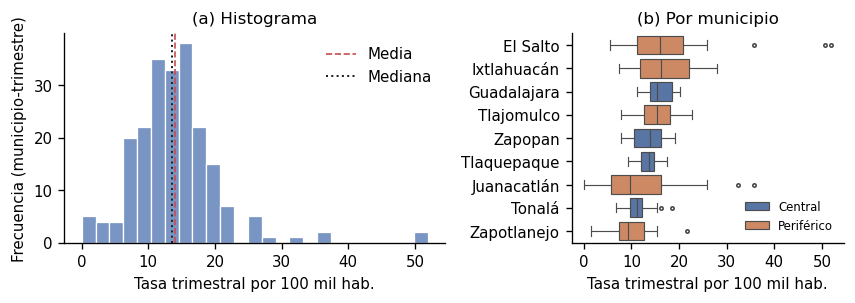

In [29]:
# Figura 1. Distribución de la tasa trimestral
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.histplot(panel["tasa_trim"], bins=25, ax=ax[0], color="#4C72B0", edgecolor="white")
ax[0].axvline(panel["tasa_trim"].mean(), color="#C44E52", ls="--", lw=1, label="Media")
ax[0].axvline(panel["tasa_trim"].median(), color="#222222", ls=":", lw=1.2, label="Mediana")
ax[0].set(xlabel="Tasa trimestral por 100 mil hab.", ylabel="Frecuencia (municipio-trimestre)", title="(a) Histograma")
ax[0].legend(frameon=False)
orden = por_mun["mun"].tolist()
sns.boxplot(data=panel, y="mun", x="tasa_trim", order=orden, hue="tipo", dodge=False, ax=ax[1],
            palette={"Central": "#4C72B0", "Periférico": "#DD8452"}, fliersize=2, linewidth=0.7)
ax[1].set(xlabel="Tasa trimestral por 100 mil hab.", ylabel="", title="(b) Por municipio")
ax[1].legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig1_tasa_univariante.pdf"); plt.show()

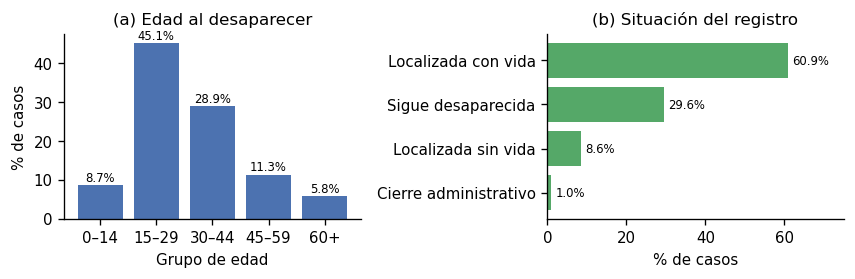

In [30]:
# Figura 2. Edad y situación
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.4))
e = fe[fe["categoria"] != "Sin dato"]
ax[0].bar(e["categoria"].astype(str).str.replace("--", "–").str.replace("60 y más", "60+"), e["pct"] * 100, color="#4C72B0")
for x, p in zip(range(len(e)), e["pct"]):
    ax[0].text(x, p * 100 + 1, f"{p*100:.1f}%", ha="center", fontsize=7)
ax[0].set(ylabel="% de casos", xlabel="Grupo de edad", title="(a) Edad al desaparecer")
s = frecuencias[frecuencias["variable"] == "Situación"].iloc[::-1]
ax[1].barh(s["categoria"], s["pct"] * 100, color="#55A868")
for y, p in enumerate(s["pct"]):
    ax[1].text(p * 100 + 1, y, f"{p*100:.1f}%", va="center", fontsize=7)
ax[1].set(xlabel="% de casos", title="(b) Situación del registro"); ax[1].set_xlim(0, 75)
fig.tight_layout(); fig.savefig(FIG / "fig2_frecuencias.pdf"); plt.show()

## 5. Gráficos multivariantes

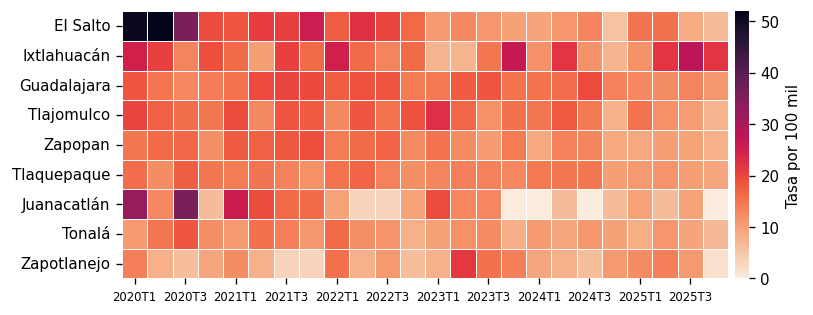

In [37]:

hm = panel.pivot(index="mun", columns="periodo", values="tasa_trim").loc[orden]
fig, ax = plt.subplots(figsize=(7.2, 2.7))
sns.heatmap(hm, cmap="rocket_r", ax=ax, cbar_kws={"label": "Tasa por 100 mil", "pad": 0.01},
            linewidths=0.3, linecolor="white")
ax.set(xlabel="", ylabel="")
ax.set_xticks(np.arange(0, 24, 2) + 0.5); ax.set_xticklabels(hm.columns[::2], rotation=0, fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig3_heatmap_mun_trim.pdf"); plt.show()

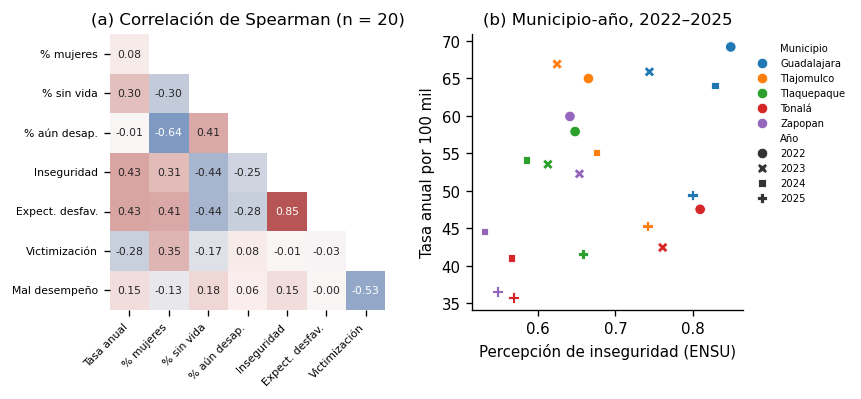

In [32]:
# Figura 4. Correlaciones
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
cplot = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(cplot, dtype=bool), 1)
sns.heatmap(cplot, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax[0],
            annot_kws={"size": 6.5}, cbar=False, square=True)
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45, ha="right")
ax[0].set_title("(a) Correlación de Spearman (n = 20)"); ax[0].tick_params(labelsize=6.5)
sns.scatterplot(data=ma_ensu.rename(columns={"mun": "Municipio", "anio": "Año"}), x="pct_inseg_ciudad", y="tasa_anual", hue="Municipio", style="Año", s=40, ax=ax[1])
ax[1].set(xlabel="Percepción de inseguridad (ENSU)", ylabel="Tasa anual por 100 mil",
          title="(b) Municipio-año, 2022–2025")
ax[1].legend(fontsize=6, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "fig4_correlaciones.pdf"); plt.show()

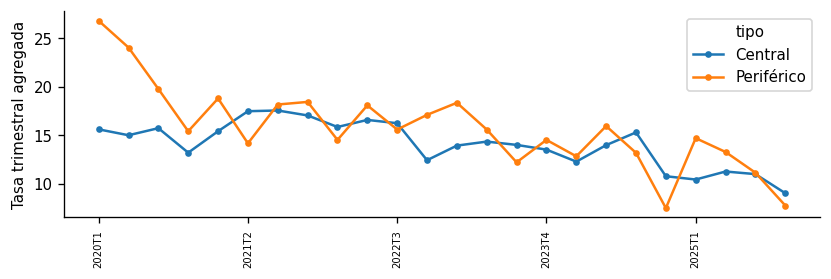

tipo,Central,Periférico
count,24.000000,24.000000
mean,14.060310,15.721844
std,2.375964,4.358827
min,9.006691,7.471767
25%,12.369027,13.231255
50%,14.153371,15.477232
75%,15.737432,18.190196
max,17.527845,26.773833


In [33]:
# Serie central vs periférico
serie = panel.groupby(["periodo", "tipo"]).apply(
    lambda x: x["casos"].sum() / x["poblacion"].sum() * 1e5, include_groups=False).unstack()
ax = serie.plot(figsize=(7, 2.4), marker="o", ms=3)
ax.set(ylabel="Tasa trimestral agregada", xlabel=""); plt.xticks(rotation=90, fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "figA_serie_tipo.pdf"); plt.show()
serie.describe()

## 6. Exportación a LaTeX

In [34]:
def n0(x): return f"{x:,.0f}"
def n2(x): return f"{x:,.2f}"

# Tabla 1: base final
with open(TAB / "tabla_base.tex", "w") as f:
    for _, r in base.iterrows():
        f.write(f"\\texttt{{{r.tabla.replace('_', chr(92)+'_')}}} & {r.contenido} & {n0(r.registros)} & {r.variables} \\\\\n")

# Tabla 2: descriptivos del panel
with open(TAB / "tabla_descriptivos.tex", "w") as f:
    for nom, r in descriptivos.iterrows():
        fmt = n0 if nom.startswith("Casos") else n2
        f.write(f"{nom} & {int(r.n)} & {fmt(r.media)} & {fmt(r.mediana)} & {fmt(r.de)} & {fmt(r['min'])} & {fmt(r['max'])} \\\\\n")
        if nom.startswith("Proporción víctima"):
            f.write("\\midrule\n")

# Tabla 3: por municipio
with open(TAB / "tabla_municipios.tex", "w") as f:
    for _, r in por_mun.iterrows():
        f.write(f"{r.mun} & {r.tipo} & {n0(r.pob)} & {n0(r.casos)} & {r.pct_casos*100:.1f} & {n2(r.tasa_media)} & {n2(r.tasa_mediana)} & {n2(r.tasa_de)} & {n2(r.tasa_min)} & {n2(r.tasa_max)} \\\\\n")

# Tabla 4: frecuencias
with open(TAB / "tabla_frecuencias.tex", "w") as f:
    prev = None
    for _, r in frecuencias.iterrows():
        if prev is not None and r.variable != prev:
            f.write("\\midrule\n")
        lab = r.variable if r.variable != prev else ""
        f.write(f"{lab} & {r.categoria} & {n0(r.n)} & {r.pct*100:.1f} \\\\\n")
        prev = r.variable
print(*[p.name for p in TAB.iterdir()])

tabla_descriptivos.tex tabla_base.tex tabla_municipios.tex tabla_frecuencias.tex


In [35]:
# Macros LaTeX
tp = tipo; pm = por_mun.set_index("mun"); dp = descriptivos
cm = lambda a, b: corr.loc[a, b]
R = {
    "TotalCasos": n0(panel["casos"].sum()),
    "PobAMG": n0(sum(POB_2020.values())),
    "CeldasConCaso": str(int((panel["casos"] > 0).sum())),
    "CeldasConENSU": str(int(panel["pct_inseg_ciudad"].notna().sum())),
    "TasaMedia": n2(panel["tasa_trim"].mean()), "TasaMediana": n2(panel["tasa_trim"].median()),
    "TasaDE": n2(panel["tasa_trim"].std()), "TasaMin": n2(panel["tasa_trim"].min()),
    "TasaMax": n2(panel["tasa_trim"].max()),
    "TasaSesgo": n2(panel["tasa_trim"].skew()),
    "TasaMaxMun": panel.loc[panel["tasa_trim"].idxmax(), "mun"],
    "TasaMaxPer": panel.loc[panel["tasa_trim"].idxmax(), "periodo"],
    "CasosMedia": n0(panel["casos"].mean()), "CasosMediana": n0(panel["casos"].median()),
    "PctMujeres": f"{(casos['sexo']=='MUJER').mean()*100:.1f}",
    "PctHombres": f"{(casos['sexo']=='HOMBRE').mean()*100:.1f}",
    "PctJovenes": f"{(casos['grupo_edad']=='15--29').mean()*100:.1f}",
    "PctMenores": f"{(casos['grupo_edad']=='0--14').mean()*100:.1f}",
    "PctSigueDesap": f"{(casos['situacion']=='Sigue desaparecida').mean()*100:.1f}",
    "PctConVida": f"{(casos['situacion']=='Localizada con vida').mean()*100:.1f}",
    "PctSinVida": f"{(casos['situacion']=='Localizada sin vida').mean()*100:.1f}",
    "TasaCentral": n2(tp.loc["Central", "tasa_agregada"]), "TasaPeriferica": n2(tp.loc["Periférico", "tasa_agregada"]),
    "MedianaCentral": n2(tp.loc["Central", "mediana"]), "MedianaPeriferica": n2(tp.loc["Periférico", "mediana"]),
    "MunTop": por_mun.iloc[0]["mun"], "MunTopTasa": n2(por_mun.iloc[0]["tasa_media"]),
    "MunTopAnual": n2(por_mun.iloc[0]["tasa_anual"]),
    "MunTopCasos": n0(por_mun.iloc[0]["casos"]), "MunTopPctCasos": f"{por_mun.iloc[0]['pct_casos']*100:.1f}",
    "MunTopPctPob": f"{por_mun.iloc[0]['pob']/sum(POB_2020.values())*100:.1f}",
    "MunLow": por_mun.iloc[-1]["mun"], "MunLowTasa": n2(por_mun.iloc[-1]["tasa_media"]),
    "RatioTopLow": f"{por_mun.iloc[0]['tasa_media']/por_mun.iloc[-1]['tasa_media']:.1f}",
    "GdlTasa": n2(pm.loc["Guadalajara", "tasa_media"]), "GdlPctCasos": f"{pm.loc['Guadalajara','pct_casos']*100:.1f}",
    "ZapTasa": n2(pm.loc["Zapopan", "tasa_media"]),
    "CVMaxMun": por_mun.sort_values("cv").iloc[-1]["mun"], "CVMax": n2(por_mun["cv"].max()),
    "CVMinMun": por_mun.sort_values("cv").iloc[0]["mun"], "CVMin": n2(por_mun["cv"].min()),
    "AnioMax": str(anual["casos"].idxmax()), "CasosAnioMax": n0(anual["casos"].max()),
    "AnioMin": str(anual["casos"].idxmin()), "CasosAnioMin": n0(anual["casos"].min()),
    "CaidaPct": f"{(anual['casos'].iloc[-1]/anual['casos'].max()-1)*-100:.1f}",
    "TasaAnualAMGMax": n2(anual["tasa"].max()), "TasaAnualAMGFin": n2(anual["tasa"].iloc[-1]),
    "PctEntreOchoVeinte": f"{panel['tasa_trim'].between(8, 20).mean()*100:.1f}",
    "CasosDE": n0(panel["casos"].std()),
    "CVCentralMin": n2(por_mun.loc[por_mun.tipo == "Central", "cv"].min()),
    "CVCentralMax": n2(por_mun.loc[por_mun.tipo == "Central", "cv"].max()),
    "CVPerMin": n2(por_mun.loc[por_mun.tipo == "Periférico", "cv"].min()),
    "CVPerMinMun": por_mun[por_mun.tipo == "Periférico"].sort_values("cv").iloc[0]["mun"],
    "CVPerMax": n2(por_mun.loc[por_mun.tipo == "Periférico", "cv"].max()),
    "CVPerMaxMun": por_mun[por_mun.tipo == "Periférico"].sort_values("cv").iloc[-1]["mun"],
    "MunTopMed": por_mun.sort_values("tasa_mediana").iloc[-1]["mun"],
    "MunTopMedTasa": n2(por_mun["tasa_mediana"].max()),
    "GdlCV": n2(pm.loc["Guadalajara", "cv"]),
    "SaltoCasosIni": n0(panel.query("mun == 'El Salto' and anio == 2020")["casos"].sum()),
    "SaltoCasosFin": n0(panel.query("mun == 'El Salto' and anio == 2025")["casos"].sum()),
    "JuanaMaxCasos": n0(panel.query("mun == 'Juanacatlán'")["casos"].max()),
    "JuanaMaxTasa": n2(panel.query("mun == 'Juanacatlán'")["tasa_trim"].max()),
    "AniosTCuatroMin": str(int((panel.groupby(["anio", "trimestre"]).apply(
        lambda x: x["casos"].sum() / x["poblacion"].sum(), include_groups=False)
        .unstack().idxmin(axis=1) == 4).sum())),
    "AniosTotal": str(panel["anio"].nunique()),
    "TrimMax": str(estac.idxmax()), "TrimMin": str(estac.idxmin()),
    "EstacMax": n2(estac.max()), "EstacMin": n2(estac.min()),
    "InsegMedia": f"{dp.loc['ENSU: percepción de inseguridad','media']*100:.1f}",
    "InsegMin": f"{dp.loc['ENSU: percepción de inseguridad','min']*100:.1f}",
    "InsegMax": f"{dp.loc['ENSU: percepción de inseguridad','max']*100:.1f}",
    "CorrTasaInseg": n2(cm("Tasa anual", "Inseguridad")),
    "CorrTasaVict": n2(cm("Tasa anual", "Victimización")),
    "CorrTasaEsp": n2(cm("Tasa anual", "Expect. desfav.")),
    "CorrTasaDesem": n2(cm("Tasa anual", "Mal desempeño")),
    "CorrInsegEsp": n2(cm("Inseguridad", "Expect. desfav.")),
    "CorrTasaSinVida": n2(cm("Tasa anual", "% sin vida")),
    "CorrTasaMujeres": n2(cm("Tasa anual", "% mujeres")),
}
with open(BASE / "resultados.tex", "w") as f:
    f.write("% Generado automáticamente por eda_desapariciones.ipynb. No editar a mano.\n")
    for k, v in R.items():
        f.write(f"\\newcommand{{\\R{k}}}{{{v}}}\n")
json.dump(R, open(BASE / "resultados.json", "w"), ensure_ascii=False, indent=1)
R

{'TotalCasos': '18,142',
 'PobAMG': '5,243,392',
 'CeldasConCaso': '212',
 'CeldasConENSU': '80',
 'TasaMedia': '14.07',
 'TasaMediana': '13.57',
 'TasaDE': '6.67',
 'TasaMin': '0.00',
 'TasaMax': '51.96',
 'TasaSesgo': '1.88',
 'TasaMaxMun': 'El Salto',
 'TasaMaxPer': '2020T2',
 'CasosMedia': '84',
 'CasosMediana': '64',
 'PctMujeres': '25.8',
 'PctHombres': '74.2',
 'PctJovenes': '45.1',
 'PctMenores': '8.7',
 'PctSigueDesap': '29.6',
 'PctConVida': '60.9',
 'PctSinVida': '8.6',
 'TasaCentral': '14.06',
 'TasaPeriferica': '15.72',
 'MedianaCentral': '13.65',
 'MedianaPeriferica': '13.28',
 'MunTop': 'El Salto',
 'MunTopTasa': '18.74',
 'MunTopAnual': '74.94',
 'MunTopCasos': '1,047',
 'MunTopPctCasos': '5.8',
 'MunTopPctPob': '4.4',
 'MunLow': 'Zapotlanejo',
 'MunLowTasa': '9.77',
 'RatioTopLow': '1.9',
 'GdlTasa': '16.00',
 'GdlPctCasos': '29.3',
 'ZapTasa': '13.55',
 'CVMaxMun': 'Juanacatlán',
 'CVMax': '0.85',
 'CVMinMun': 'Tlaquepaque',
 'CVMin': '0.16',
 'AnioMax': '2021',
 'Cas

In [36]:
print(anual.round(2)); print(estac.round(2)); print(por_mun[["mun","tasa_media","cv"]].round(2))
print(corr.round(2))

      casos   tasa  var_pct
anio                       
2020   3415  65.13      NaN
2021   3557  67.84     0.04
2022   3246  61.91    -0.09
2023   2976  56.76    -0.08
2024   2707  51.63    -0.09
2025   2241  42.74    -0.17
trimestre
1    15.12
2    14.83
3    14.37
4    11.96
Name: tasa_trim, dtype: float64
           mun  tasa_media    cv
3     El Salto       18.74  0.64
1  Ixtlahuacán       16.86  0.37
0  Guadalajara       16.00  0.17
4   Tlajomulco       15.36  0.24
7      Zapopan       13.55  0.25
5  Tlaquepaque       13.44  0.16
2  Juanacatlán       11.48  0.85
6       Tonalá       11.43  0.24
8  Zapotlanejo        9.77  0.47
                 Tasa anual  % mujeres  % sin vida  % aún desap.  Inseguridad  Expect. desfav.  Victimización  Mal desempeño
Tasa anual             1.00       0.08        0.30         -0.01         0.43             0.43          -0.28           0.15
% mujeres              0.08       1.00       -0.30         -0.64         0.31             0.41           0.35 